# 05 · Statistical validation
Why the naive test cannot be trusted on a daily panel, and what calibrates it: p-value histograms and λ under the null, multiplicity correction before/after, effect sizes with block-bootstrap intervals.

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from synera_core.config import find_repo_root, get_settings
warnings.filterwarnings("ignore")
ROOT = find_repo_root()
C = dict(bg="#061424", panel="#0b2037", cyan="#16B5FF", green="#6FD65B", amber="#FFB547", red="#FF4D5E", teal="#19E3B1", text="#EAF2FB", muted="#8FA6BF")
plt.rcParams.update({"figure.facecolor": C["bg"], "axes.facecolor": C["bg"], "axes.edgecolor": C["muted"], "axes.labelcolor": C["text"],
    "text.color": C["text"], "xtick.color": C["muted"], "ytick.color": C["muted"], "grid.color": "#1c3a5c", "axes.grid": True, "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=[C["cyan"], C["green"], C["amber"], C["red"], C["teal"]]), "figure.dpi": 110, "font.size": 9})
SEED = get_settings().seeds.global_seed
RES = ROOT / "artifacts" / "results"

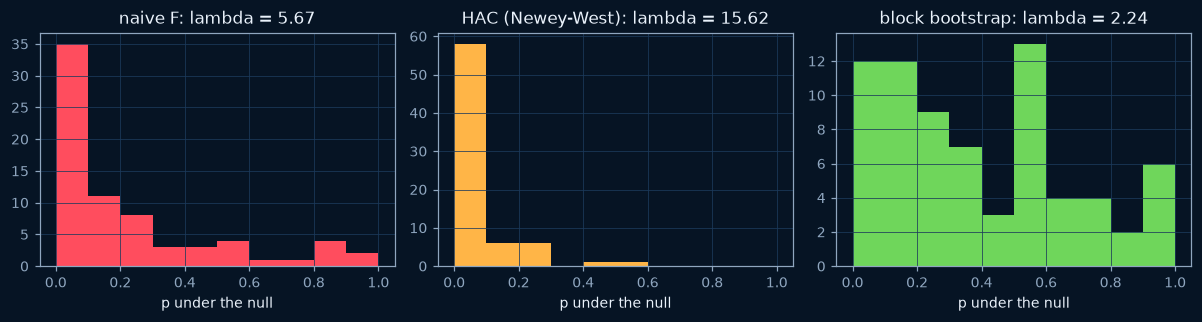

In [2]:
from scipy import stats
from synera_core.benchmark.generator import STRESSORS, load_env_panel, simulate_benchmark, standardise_per_city
from synera_core.discovery.panel import PanelDiscovery
env = standardise_per_city(load_env_panel())
naive, hac, boot = [], [], []
for s in range(8):
    df, _ = simulate_benchmark(env, snr=2.0, seed=500 + s, null=True)
    d = PanelDiscovery(df, "outcome", STRESSORS, n_boot=199, seed=s)
    for pair in d.pairs[::5]:
        j = d._test_pair(*pair).joint; naive.append(j.p_naive); hac.append(j.p_hac); boot.append(j.p_boot)
lam = lambda p: np.median(stats.chi2.isf(np.clip(p, 1e-300, 1), 1)) / stats.chi2.ppf(0.5, 1)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, nm, p, col in zip(axes, ["naive F", "HAC (Newey-West)", "block bootstrap"], [naive, hac, boot], [C["red"], C["amber"], C["green"]]):
    ax.hist(p, bins=10, range=(0, 1), color=col); ax.set_title(f"{nm}: lambda = {lam(np.array(p)):.2f}"); ax.set_xlabel("p under the null")
plt.tight_layout(); plt.show()

A flat histogram and λ ≈ 1 mean honest p-values. The naive F spikes near zero (false alarms); a 16-restriction Newey-West test is worse still with persistent regressors; the block-bootstrap-calibrated test is closest to honest.

In [3]:
from synera_core.validation.multitest import bh_fdr
p = np.array(boot); q = bh_fdr(p)
print(f"null tests: {len(p)}; raw p<0.05: {(p < 0.05).sum()}; after BH q<0.05: {(q < 0.05).sum()}")

null tests: 72; raw p<0.05: 5; after BH q<0.05: 1


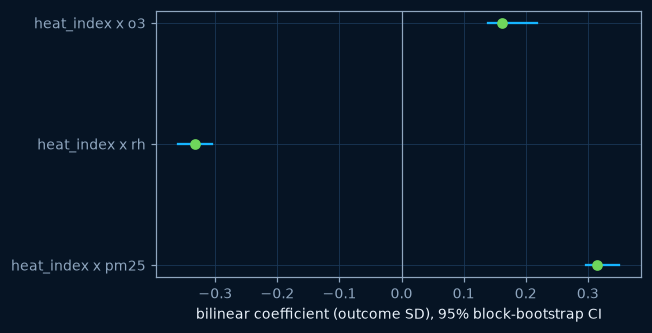

In [4]:
from synera_core.pipeline.registry import get_spec, load_panel
from synera_core.discovery.stack import run_full_stack
res = run_full_stack(load_panel(get_spec("benchmark_track_b")), "outcome", STRESSORS, n_boot=99, n_ci=100, seed=SEED)
acc = [r for r in res["pairs"] if r["s3_conditional"]]
fig, ax = plt.subplots(figsize=(6, 0.7 * max(len(acc), 1) + 1))
for i, r in enumerate(acc):
    ax.plot([r["ci_low"], r["ci_high"]], [i, i], color=C["cyan"]); ax.plot(r["b_AB_std"], i, "o", color=C["green"])
ax.axvline(0, color=C["muted"], lw=0.8); ax.set_yticks(range(len(acc)), [f"{r['a']} x {r['b']}" for r in acc]); ax.set_xlabel("bilinear coefficient (outcome SD), 95% block-bootstrap CI"); plt.tight_layout(); plt.show()